In [1]:
import numpy as np
import os
from tqdm import tqdm
import matplotlib.pyplot as plt

In [3]:
path = '/home/kale-chen/Documents/PET/MDA_04112026/run1coinc.bin'
num_rows = os.path.getsize(path) // 12
data = np.memmap(path, dtype = np.int16, mode = 'r', shape = (num_rows, 6))
print(data[0:3])
print(num_rows)

[[ 1617  1475  1883  1463 -1822     0]
 [ 2226  1551  1950  2300  1598     0]
 [ 2226  1551  1758  2407  1781     0]]
3487989


In [41]:
eventcounts = np.zeros((3072, 3072), dtype = np.int32)
for i in tqdm(range(0, num_rows, 1000000)):
    chunk = data[i:i+1000000]
    chunk = chunk[chunk[:, 5] > 50]
    np.add.at(eventcounts, (chunk[:, 1], chunk[:, 3]), 1)
print(np.sum(eventcounts))

100%|██████████| 4/4 [00:00<00:00, 22.52it/s]

1029712


In [43]:
bigidls = []
for i in range(3072):
    if np.sum(eventcounts[i]) > 500:
        bigidls.append(i)
print(len(bigidls))  


147


100%|██████████| 4/4 [00:00<00:00, 280.37it/s]

746


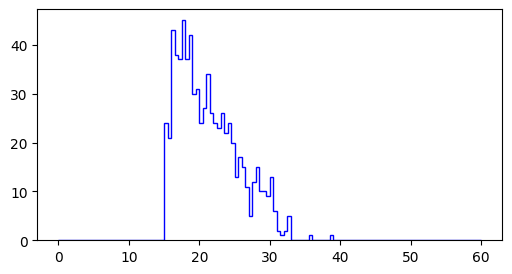

In [79]:
randomidl = np.random.choice(bigidls)
idl = randomidl
energies = []
for i in tqdm(range(0, num_rows, 1000000)):
    chunk = data[i:i+1000000]
    chunk = chunk[chunk[:, 5] > 50]
    chunk = chunk[chunk[:, 1] == idl]
    energies.extend(chunk[:, 2] / 100)
print(len(energies))
plt.figure(figsize = (6, 3))
plt.hist(energies, bins = np.linspace(0, 60, 121), color = 'blue', histtype = 'step')
plt.show()